# 06 Statistical Modelling 1: Linear Regression
This notebook will fit a weighted linear regression models for FHVHV wait time, and predicts raw wait time on a log scale. 

- We may expect this statistical model to be more of an interpretive model than predictive, as it enforces linearity, making feature effects easy to explain, but limits the model's complexity and ability to capture nonlinear relationships. Nevertheless, we will make predictions with this model to compare with the machine learning model evaluation later.
- We will assign a higher weight to alert rows for balance (rows with alert is ~2% of all rows), s.t. the model does not overrepresent for non-alert rows during fitting, as our primary goal is to interpret / predict in the context of when an alert arises. 



In [60]:
# Restart spark if required
try:
    spark.stop()
except NameError:
    pass
except Exception:
    pass

from pyspark.sql import SparkSession

# Create a spark session (which will run spark jobs)
spark = (
    SparkSession.builder.appName("MAST30034 Project 1")
    .config("spark.sql.repl.eagerEval.enabled", True) 
    .config("spark.sql.parquet.cacheMetadata", "true")
    .config("spark.sql.session.timeZone", "America/New_York") # timezone set to NYC
    .getOrCreate()
)
spark.conf.set("spark.sql.shuffle.partitions", "800")
spark.conf.set("spark.sql.adaptive.enabled", "true")

spark.sparkContext.setLogLevel("ERROR") # silence warnings

## Set up and configuration

In [61]:
# Imports
from pyspark.sql import functions as F

from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns


In [62]:
# Raw spatial data from `01_fetch_data.ipynb`
taxi_zones_path = "../data/raw/taxi_zones/taxi_zones.shp"

# Input directories from `02_preprocess_data.ipynb`
processed_dir = "../data/processed"

# Input directories from `03_feature_engineering.ipynb`
features_dir = "../data/features"

# Output directories for `05_exploratory_analysis.ipynb`
analysis_dir = "../data/analysis"

In [63]:
sdf_tlc_hourly = spark.read.parquet(f"{analysis_dir}/tlc_zone_hourly_temporal")
sdf_tlc_hourly.show(5)

+-------------------+------------+------------+---------------+-------------+----------------+-------------------+---------+----------------+----------+---------+--------+-------------------+----+----------------+-------------------+-----------+-----------+------------+
|               hour|PULocationID|n_trips_taxi|gross_fare_taxi|n_trips_fhvhv|gross_fare_fhvhv|avg_wait_time_fhvhv|  borough|       taxi_zone|n_stations|ridership|n_alerts|disruption_severity|coco|weather_severity|              month|hour_of_day|day_of_week|hour_of_week|
+-------------------+------------+------------+---------------+-------------+----------------+-------------------+---------+----------------+----------+---------+--------+-------------------+----+----------------+-------------------+-----------+-----------+------------+
|2026-03-26 17:00:00|          94|           0|           0.00|           81|         1873.83|             406.67|    Bronx|   Fordham South|         2|      339|       0|                

## Preparing inputs for `pyspark.ml` linear regression
- build the features vector with numeric and categorical (one-hot-encoded) features
- include temporal (`month_num`, `hour_of_week`) and spatial (`PULocationID`) predictors as we may expect wait time to differs strongly by zone, month, and weekly time pattern, in addition to the alert signal
- train-test split for 2025 vs. 2026 respectively 
- assign higher weight to underrepresented alerts instances (PULocation, hour) to balance for alerts row prediction error

In [64]:
# Build base modelling table
base_df = (
    sdf_tlc_hourly
    .filter(F.col("avg_wait_time_fhvhv").isNotNull())
    .withColumn("year", F.year("hour"))
    .withColumn("month_num", F.month("hour").cast("string"))
    .withColumn("hour_of_day", F.col("hour_of_day").cast("string"))
    .withColumn("hour_of_week", F.col("hour_of_week").cast("string"))
    .withColumn("PULocationID", F.col("PULocationID").cast("string"))
    .withColumn("has_alert", (F.col("n_alerts") > 0).cast("int"))
    .withColumn("log_ridership", F.log1p("ridership"))
    .withColumn("label_log_wait", F.log1p("avg_wait_time_fhvhv"))

    # Manhattan is the baseline reference borough for interaction interpretation
    .withColumn("alert_bronx", F.when(F.col("borough") == "Bronx", F.col("has_alert")).otherwise(0))
    .withColumn("alert_brooklyn", F.when(F.col("borough") == "Brooklyn", F.col("has_alert")).otherwise(0))
    .withColumn("alert_queens", F.when(F.col("borough") == "Queens", F.col("has_alert")).otherwise(0))
    .withColumn("severity_bronx", F.when(F.col("borough") == "Bronx", F.col("disruption_severity")).otherwise(0))
    .withColumn("severity_brooklyn", F.when(F.col("borough") == "Brooklyn", F.col("disruption_severity")).otherwise(0))
    .withColumn("severity_queens", F.when(F.col("borough") == "Queens", F.col("disruption_severity")).otherwise(0))
)


In [65]:
# Train test split 
train_base = base_df.filter(F.col("year") == 2025) # train (12 months)
test_base = base_df.filter(F.col("year") == 2026)  # test (5 months)

# Split into rows with / without alerts
n_alert_train = train_base.filter(F.col("has_alert") == 1).count()
n_no_alert_train = train_base.filter(F.col("has_alert") == 0).count()

# Assign weighting for rows with alert, add to train and test
alert_weight = n_no_alert_train / n_alert_train

train_base = train_base.withColumn(
    "sample_weight",
    F.when(F.col("has_alert") == 1, F.lit(alert_weight)).otherwise(F.lit(1.0))
)

test_base = test_base.withColumn("sample_weight", F.lit(1.0))

# Print for reference
print(f"Alert training rows:    {n_alert_train:,}")
print(f"No-alert training rows: {n_no_alert_train:,}")
print(f"Alert row weight:       {alert_weight:.2f}")


Alert training rows:    34,076
No-alert training rows: 1,293,947
Alert row weight:       37.97


In [ ]:
# Group predictors to categorical or numerical
categorical_cols = [
    "PULocationID",
    "month_num",
    "hour_of_week",
]

numeric_cols = [
    "n_stations",
    "log_ridership",
    "weather_severity",
    "has_alert",
    "disruption_severity",
    "alert_bronx",
    "alert_brooklyn",
    "alert_queens",
    "severity_bronx",
    "severity_brooklyn",
    "severity_queens",
]

# Turn text categories to numeric categories (e.g. Bronx -> 0, Brooklyn -> 1)
indexers = [StringIndexer(inputCol=col, outputCol=f"{col}_idx", handleInvalid="error") for col in categorical_cols] # don't make unseen bucket (won't have unseen zone/time in test)

# Turn numeric categories to one-hot-encoding binary indicator variables 
encoders = [OneHotEncoder(inputCol=f"{col}_idx", outputCol=f"{col}_oh", dropLast=True) for col in categorical_cols] # dropLast column removes unseen bucket

# Combine all numeric and categorical (one-hot) categories to features vector for sparkml
assembler = VectorAssembler(
    inputCols=numeric_cols + [f"{col}_oh" for col in categorical_cols],
    outputCol="features"
)


## Fit linear regression model with `pyspark.ml`
- fit regression model with compiled features vector 
- evaluate on both log and raw scales using RMSE, MAE, and $R^2$
- examine the fitted coefficients; particularly interaction term coefficients, which may suggest how wait time differs by month, zone, and weekly time pattern 

In [67]:
# Fit weighted linear regression model
lr = LinearRegression(
    featuresCol="features",
    labelCol="label_log_wait",
    predictionCol="pred_log_wait",
    weightCol="sample_weight",
    regParam=0.0,
    elasticNetParam=0.0
)

pipeline = Pipeline(stages=indexers + encoders + [assembler, lr])

model_linreg = pipeline.fit(train_base)

pred_linreg = (
    model_linreg
    .transform(test_base)
    .withColumn("pred_wait_seconds", F.expm1("pred_log_wait"))
)

In [68]:
# Evaluate on log scale
rmse_log = RegressionEvaluator(
    labelCol="label_log_wait",
    predictionCol="pred_log_wait",
    metricName="rmse"
).evaluate(pred_linreg)

mae_log = RegressionEvaluator(
    labelCol="label_log_wait",
    predictionCol="pred_log_wait",
    metricName="mae"
).evaluate(pred_linreg)

r2_log = RegressionEvaluator(
    labelCol="label_log_wait",
    predictionCol="pred_log_wait",
    metricName="r2"
).evaluate(pred_linreg)

# Evaluate on original seconds scale
rmse_seconds = RegressionEvaluator(
    labelCol="avg_wait_time_fhvhv",
    predictionCol="pred_wait_seconds",
    metricName="rmse"
).evaluate(pred_linreg)

mae_seconds = RegressionEvaluator(
    labelCol="avg_wait_time_fhvhv",
    predictionCol="pred_wait_seconds",
    metricName="mae"
).evaluate(pred_linreg)

r2_seconds = RegressionEvaluator(
    labelCol="avg_wait_time_fhvhv",
    predictionCol="pred_wait_seconds",
    metricName="r2"
).evaluate(pred_linreg)

# Evaluate alert-affected rows separately
alert_pred_linreg = pred_linreg.filter(F.col("has_alert") == 1)

alert_mae_seconds = RegressionEvaluator(
    labelCol="avg_wait_time_fhvhv",
    predictionCol="pred_wait_seconds",
    metricName="mae"
).evaluate(alert_pred_linreg)

alert_rmse_seconds = RegressionEvaluator(
    labelCol="avg_wait_time_fhvhv",
    predictionCol="pred_wait_seconds",
    metricName="rmse"
).evaluate(alert_pred_linreg)

print("Linear Regression: log1p(avg_wait_time_fhvhv)")
print(f"RMSE log scale:        {rmse_log:.4f}")
print(f"MAE log scale:         {mae_log:.4f}")
print(f"R2 log scale:          {r2_log:.4f}")
print()
print("Linear Regression: wait time in seconds")
print(f"RMSE seconds:          {rmse_seconds:.2f}")
print(f"MAE seconds:           {mae_seconds:.2f}")
print(f"R2 seconds:            {r2_seconds:.4f}")
print()
print("Alert-affected rows only")
print(f"Alert-hour RMSE sec:   {alert_rmse_seconds:.2f}")
print(f"Alert-hour MAE sec:    {alert_mae_seconds:.2f}")
print(f"Alert rows:            {alert_pred_linreg.count():,}")

Linear Regression: log1p(avg_wait_time_fhvhv)
RMSE log scale:        0.2481
MAE log scale:         0.1805
R2 log scale:          0.1881

Linear Regression: wait time in seconds
RMSE seconds:          97.71
MAE seconds:           60.38
R2 seconds:            0.1262

Alert-affected rows only
Alert-hour RMSE sec:   100.94
Alert-hour MAE sec:    59.80
Alert rows:            16,063


In [69]:
# Extract fitted coefficients
fitted_lr = model_linreg.stages[-1]

feature_attrs = (
    model_linreg
    .transform(train_base.limit(1))
    .schema["features"]
    .metadata["ml_attr"]["attrs"]
)

feature_names = []
for attr_type in feature_attrs:
    feature_names += [attr["name"] for attr in feature_attrs[attr_type]]

coef_linreg = (
    pd.DataFrame({
        "feature": feature_names,
        "coefficient": fitted_lr.coefficients.toArray()
    })
    .sort_values("coefficient", ascending=False)
)

coef_linreg

,feature,coefficient
129,PULocationID_oh_90,0.715244
19,PULocationID_oh_143,0.517606
106,PULocationID_oh_60,0.367893
67,PULocationID_oh_236,0.341832
158,month_num_oh_6,0.205269
...,...,...
30,PULocationID_oh_162,-0.798690
41,PULocationID_oh_177,-0.815303
28,PULocationID_oh_159,-0.826247
94,PULocationID_oh_33,-0.841824


The extracted coefficients have highest absolute coefficients in categorical one-hot encoded columns from `PULocationID` and `month_num`. This suggests that the temporal and spatial features explain more wait-time variation than simply subway alerts / disruption severity level, which is very plausible given alert rows are only 2% of the data, and in the real life context, wait time is indeed highly influenced by the WHERE and WHEN, in addition to disruption severity level. 

We can use disruption-related coefficients (interaction) to examine whether disruption features still explain additional wait-time pressure.

In [76]:
# Key disruption-related coefficients
coef_linreg[
    coef_linreg["feature"].str.contains(
        "alert|severity|ridership|weather",
        case=False
    )
]

,feature,coefficient
330,log_ridership,0.172108
338,severity_brooklyn,0.076512
332,has_alert,0.016512
339,severity_queens,0.010240
335,alert_brooklyn,-0.007811
336,alert_queens,-0.023903
334,alert_bronx,-0.024739
337,severity_bronx,-0.050040
333,disruption_severity,-0.088213
331,weather_severity,-0.096592


The disruption related coefficients give insight into how disruption severity effects each borough,with respect to Manhattan (encoded as baseline in `disruption_severity`). The interaction terms show additional effects relative to Manhattan, clear increases for Bronx (+16%), Brookly (+11%) and Queens (+6%). This suggests that, for the same increase in disruption severity, wait times rise more sharply in these outer boroughs than in Manhattan, especially in the Bronx and Brooklyn.

$$
\begin{align}
\text{Manhattan}&: \exp(0.096) - 1 &\approx +10.1\% \text{ per severity unit} \\
\text{Bronx}&: \exp(0.096 + 0.162) - 1 &\approx +29.4\% \text{ per severity unit}\\
\text{Brooklyn}&: \exp(0.096 + 0.111) - 1 &\approx +23.0\% \text{ per severity unit}\\
\text{Queens}&: \exp(0.096 + 0.069) - 1 &\approx +17.9\% \text{ per severity unit}
\end{align}
$$

# STILL DRAFTING

In [77]:
# Check all indexer columns for each categorical feature
for col, indexer_model, encoder_model in zip(
    categorical_cols,
    model_linreg.stages[:len(categorical_cols)],
    model_linreg.stages[len(categorical_cols):2 * len(categorical_cols)]
):
    print(col)
    print("StringIndexer labels:", indexer_model.labels)
    print("OneHotEncoder category sizes:", encoder_model.categorySizes)
    print()

PULocationID
StringIndexer labels: ['100', '106', '107', '108', '112', '113', '114', '116', '117', '123', '126', '127', '129', '130', '132', '134', '14', '141', '142', '143', '144', '145', '146', '147', '148', '149', '151', '152', '159', '161', '162', '163', '164', '165', '166', '167', '168', '169', '17', '173', '174', '177', '18', '181', '185', '186', '188', '189', '193', '197', '198', '21', '210', '212', '216', '217', '22', '220', '223', '225', '226', '227', '228', '231', '232', '234', '235', '236', '237', '238', '239', '24', '241', '242', '243', '244', '246', '247', '248', '249', '25', '250', '254', '255', '256', '258', '259', '26', '260', '261', '263', '28', '29', '32', '33', '35', '36', '37', '39', '41', '42', '45', '48', '49', '51', '55', '60', '61', '62', '63', '65', '66', '68', '69', '7', '71', '74', '75', '76', '77', '78', '79', '80', '81', '82', '85', '86', '87', '89', '90', '92', '94', '95', '97', '125', '133', '180', '196', '230', '257', '3', '88', '183', '40', '153', '178'

In [73]:
# Zone coefficient heat/map table
zone_coef = (
    coef_linreg[
        coef_linreg["feature"].str.contains("PULocationID_oh_", case=False, regex=False)
    ]
    .copy()
)

zone_coef["PULocationID"] = (
    zone_coef["feature"]
    .str.replace("PULocationID_oh_", "", regex=False)
    .astype(int)
)

zone_coef = zone_coef.sort_values("coefficient", ascending=False)
zone_coef.head(20)

,feature,coefficient,PULocationID
129,PULocationID_oh_90,0.715244,90
19,PULocationID_oh_143,0.517606,143
106,PULocationID_oh_60,0.367893,60
67,PULocationID_oh_236,0.341832,236
47,PULocationID_oh_189,0.133999,189
108,PULocationID_oh_62,0.071760,62
2,PULocationID_oh_107,0.041410,107
1,PULocationID_oh_106,0.037592,106
139,PULocationID_oh_257,0.036660,257
85,PULocationID_oh_258,0.034138,258


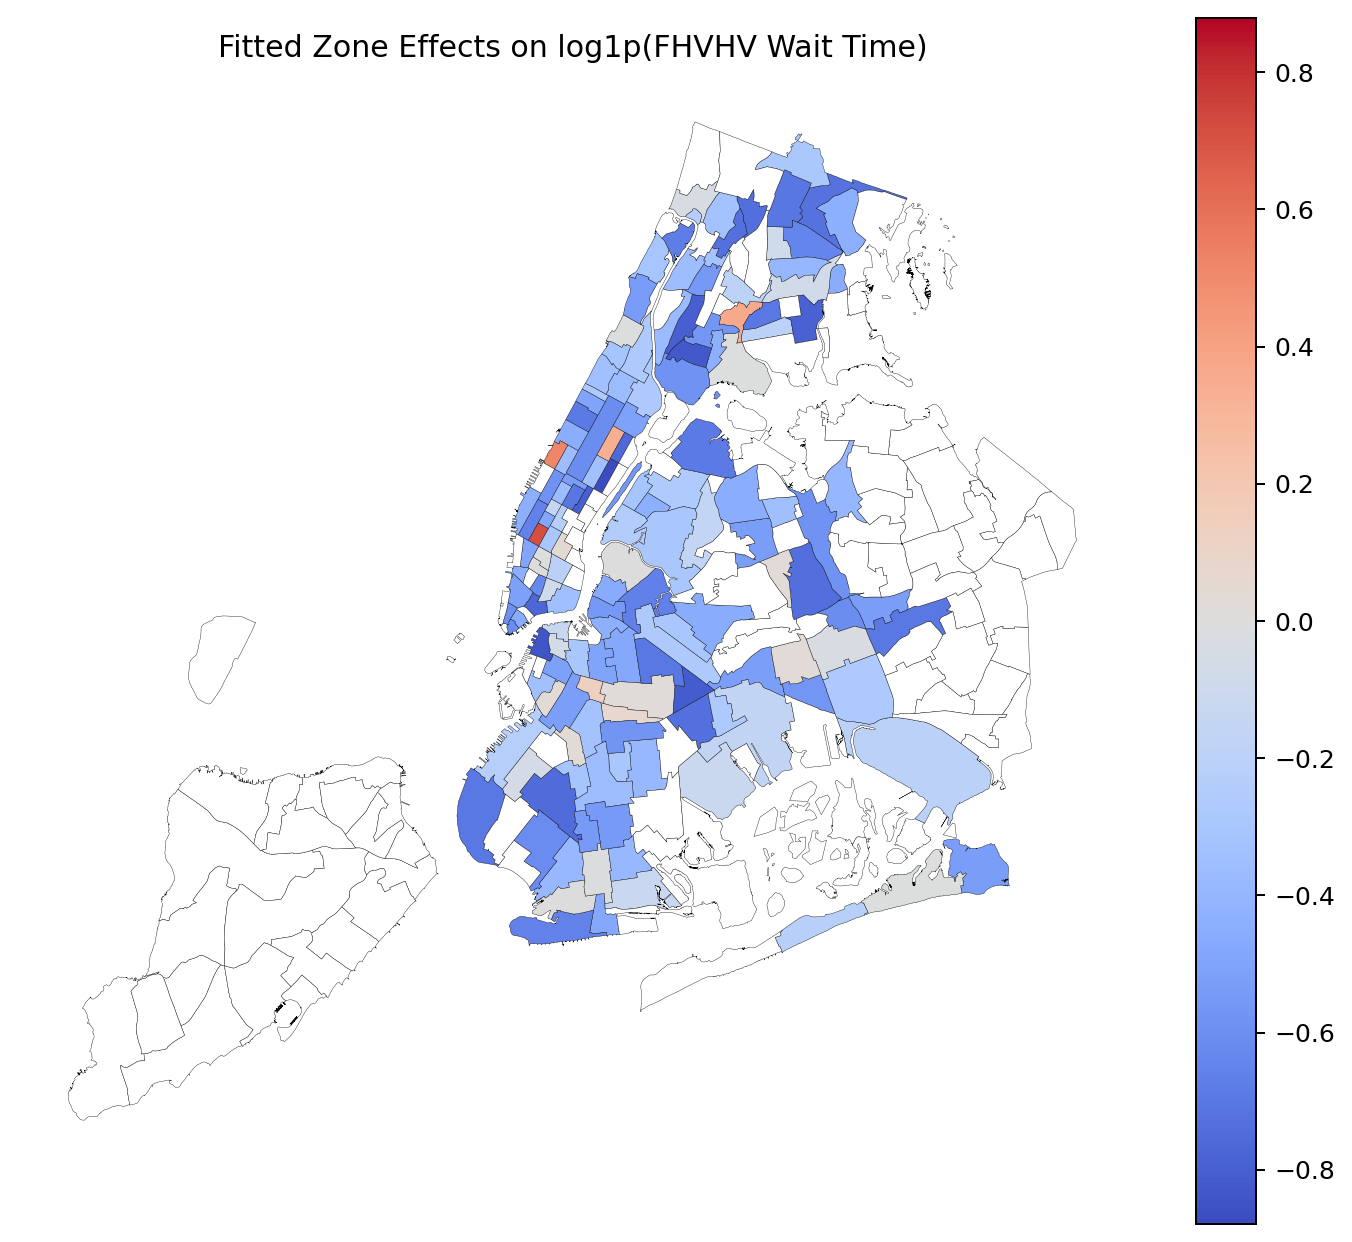

In [ ]:
# Plot PULocationID coefficients to visualise fitted zone-level wait-time differences relative to the reference zone
zones = gpd.read_file(taxi_zones_path)[["LocationID", "borough", "zone", "geometry"]]

zone_coef_geo = zones.merge(
    zone_coef,
    left_on="LocationID",
    right_on="PULocationID",
    how="left"
)

coef_abs_max = zone_coef_geo["coefficient"].abs().max()

fig, ax = plt.subplots(figsize=(8, 7), dpi=180)

zone_coef_geo.plot(
    ax=ax,
    column="coefficient",
    cmap="coolwarm",
    vmin=-coef_abs_max,
    vmax=coef_abs_max,
    legend=True,
    edgecolor="black",
    linewidth=0.15,
    missing_kwds={"color": "white", "edgecolor": "black", "label": "No coefficient"}
)

ax.set_title("Fitted Zone Effects on log1p(FHVHV Wait Time)")
ax.axis("off")
plt.tight_layout()
plt.show()

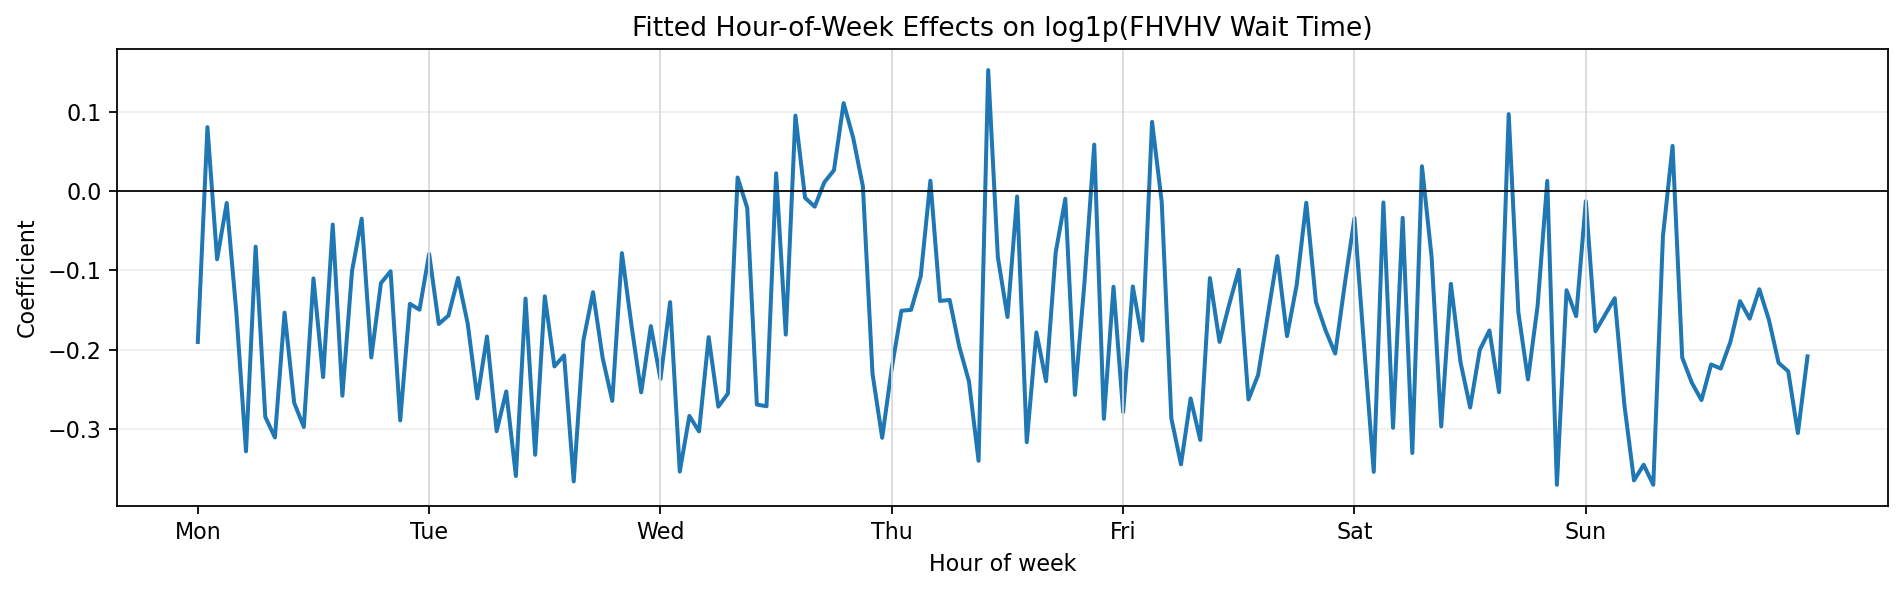

In [ ]:
# Plot hour_of_week coefficients to visualise fitted wait-time differences relative to the reference hour-of-week
hour_coef = (
    coef_linreg[
        coef_linreg["feature"].str.contains("hour_of_week_oh_", case=False, regex=False)
    ]
    .copy()
)

hour_coef["hour_of_week"] = (
    hour_coef["feature"]
    .str.replace("hour_of_week_oh_", "", regex=False)
    .astype(int)
)

hour_coef = hour_coef.sort_values("hour_of_week")

plt.figure(figsize=(12, 3.8), dpi=160)

sns.lineplot(
    data=hour_coef,
    x="hour_of_week",
    y="coefficient",
    linewidth=1.8
)

for x in [24, 48, 72, 96, 120, 144]:
    plt.axvline(x, color="0.85", linewidth=0.8)

plt.axhline(0, color="black", linewidth=0.8)
plt.xticks([0, 24, 48, 72, 96, 120, 144], ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
plt.xlabel("Hour of week")
plt.ylabel("Coefficient")
plt.title("Fitted Hour-of-Week Effects on log1p(FHVHV Wait Time)")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()